# AG News · Part 2: News-category Classification with LSTM/GRU
**Author:** Marco Larriba Rius

We classify AG News articles into the **4 categories** (World, Sports, Business, Sci/Tech) with deep
recurrent networks, **reusing the embeddings trained in Part 1** (no external/pretrained vectors).
We compare LSTM-only and GRU-only architectures over two embedding representations, pick the best by
quality metrics, and build an analyser for multiple related sentences.

> **Framework:** PyTorch on **GPU (CUDA)**. Requires `embeddings_MLR.npz` from Part 1.
> `N_SAMPLES = None` uses the full corpus; set it to e.g. `40000` for a quick smoke test.

In [12]:
# ============================================================================
# Setup: libraries, reproducibility seed, global plot style and constants
# ============================================================================
import numpy as np
import pandas as pd
import re
import random
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

import torch
import torch.nn as nn

sns.set_theme(style='whitegrid', palette='muted', font_scale=0.9)
plt.rcParams.update({'figure.dpi': 130, 'axes.spines.top': False, 'axes.spines.right': False})

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU only')

DATA_PATH   = 'news_dataset.csv'
FIGURES_DIR = Path('figures'); FIGURES_DIR.mkdir(exist_ok=True)
CLASS_NAMES = ['World', 'Sports', 'Business', 'Sci/Tech']

# Config
MAX_LEN   = 40
EPOCHS    = 10
BATCH     = 512
N_SAMPLES = None    # None = full corpus; set e.g. 40000 to smoke-test

Device: cuda | NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Load data, reuse the Part 1 embeddings and split

In [13]:
# Load the corpus (optionally a balanced subsample for a quick test)
df = pd.read_csv(DATA_PATH)
df['text'] = df['Title'].fillna('') + '. ' + df['Description'].fillna('')
df['y']    = df['Class Index'] - 1   # labels 0..3
if N_SAMPLES:
    df = (df.groupby('y', group_keys=False)
            .apply(lambda g: g.sample(min(len(g), N_SAMPLES // 4), random_state=SEED))
            .reset_index(drop=True))
print('Working sample:', df.shape, '| per class:', df['y'].value_counts().to_dict())

Working sample: (120000, 5) | per class: {2: 30000, 3: 30000, 1: 30000, 0: 30000}


### 1.1 Reuse two embeddings from Part 1
We fix the **context window at 6** and contrast only the **embedding dimension**: `d312_w6`
vs `d752_w6`. It is a **controlled comparison** - the only thing that changes between the two
is the dimension - so any difference in classification is attributable to it. (Part 1 found
d312 separates the news classes slightly better than d752; here we test whether that carries
over to the downstream task.) No external/pretrained vectors are used.

In [14]:
# Load the embeddings produced by Part 1 and choose two representations
emb = np.load('embeddings_MLR.npz', allow_pickle=True)
vocab = list(emb['vocab']); word2idx = {w: i for i, w in enumerate(vocab)}
PAD_IDX = len(vocab)                       # extra index used for padding (zero vector)
available = [k for k in emb.files if k != 'vocab']
print('Embeddings available from Ex.1:', available)

CHOSEN = ['d312_w6', 'd752_w6'] if set(['d312_w6', 'd752_w6']).issubset(available) else available[:2]
print('Chosen for Ex.2:', CHOSEN, '-> same window (6), contrast embedding dimension 312 vs 752')

def padded_matrix(key):
    """Embedding matrix with an extra zero row at PAD_IDX for padding."""
    M = emb[key]
    return np.vstack([M, np.zeros((1, M.shape[1]), dtype=M.dtype)]).astype('float32')

Embeddings available from Ex.1: ['d312_w2', 'd752_w2', 'd312_w4', 'd752_w4', 'd312_w6', 'd752_w6']
Chosen for Ex.2: ['d312_w6', 'd752_w6'] -> same window (6), contrast embedding dimension 312 vs 752


### 1.2 Encode the text and make a stratified 70/15/15 split

In [15]:
# Clean, encode to ids, pad to a fixed length and split into train/val/test
STOP = set(("the a an and or to of in for on at by with from is are was were be been being this that these those "
            "it its as has have had he she they we you i his her their our your not but if then than so over after about "
            "into out up down one two will would can could said more most other new "
            "reuters ap afp reut monday tuesday wednesday thursday friday saturday sunday "
            "january february march april june july august september october november december "
            "first last says year update against who three four five six seven eight nine ten "
            "yesterday today tomorrow week weeks day days month months inc corp ltd also may "
            "time when where what how why").split())

def clean(s):
    """Lowercase, remove HTML/agency/date noise and return meaningful tokens (>2 chars, no stopwords)."""
    s = re.sub(r'&[a-z]+;|quot|#39|lt|gt', ' ', str(s).lower())
    return [w for w in re.findall(r'[a-z]+', s) if len(w) > 2 and w not in STOP]

def encode_pad(s):
    """Clean -> ids -> post-pad/truncate to MAX_LEN (PAD_IDX for padding)."""
    ids = [word2idx[w] for w in clean(s) if w in word2idx][:MAX_LEN]
    return ids + [PAD_IDX] * (MAX_LEN - len(ids))

X = np.array([encode_pad(t) for t in df['text']], dtype=np.int64)
y = df['y'].values.astype(np.int64)

def strat_split(y, fracs=(0.70, 0.15), seed=SEED):
    """Stratified train/val/test index split (no sklearn)."""
    rng = np.random.default_rng(seed); tr, va, te = [], [], []
    for c in np.unique(y):
        idx = np.where(y == c)[0]; rng.shuffle(idx); n = len(idx)
        a, b = int(fracs[0] * n), int((fracs[0] + fracs[1]) * n)
        tr += list(idx[:a]); va += list(idx[a:b]); te += list(idx[b:])
    rng.shuffle(tr); rng.shuffle(va); rng.shuffle(te)
    return np.array(tr), np.array(va), np.array(te)

i_tr, i_va, i_te = strat_split(y)
X_tr, y_tr = X[i_tr], y[i_tr]
X_val, y_val = X[i_va], y[i_va]
X_te, y_te = X[i_te], y[i_te]
print('Split -> train', X_tr.shape, 'val', X_val.shape, 'test', X_te.shape)
print('Justification: 70/15/15 stratified -> enough data to train recurrent nets while keeping '
      'balanced, independent val/test sets for honest model selection and final evaluation.')

Split -> train (84000, 40) val (18000, 40) test (18000, 40)
Justification: 70/15/15 stratified -> enough data to train recurrent nets while keeping balanced, independent val/test sets for honest model selection and final evaluation.


## 2. LSTM and GRU architectures over the two embeddings
A **frozen** embedding layer is initialised with each learned matrix. We train **four networks**
= {LSTM, GRU} x {`d312_w6`, `d752_w6`}. Within each cell type the two embeddings share the same
architecture, so the **embedding comparison is controlled**; across cell types we also vary the
number of recurrent layers and the learning rate. Masked mean-pooling over the recurrent outputs
ignores the padding positions.

In [16]:
# Recurrent classifier (LSTM-only or GRU-only) on top of a frozen pretrained embedding
class RNNClassifier(nn.Module):
    def __init__(self, emb_matrix, kind, n_layers=1, hidden=64, dropout=0.3, num_classes=4):
        super().__init__()
        V, D = emb_matrix.shape
        w = torch.tensor(emb_matrix, dtype=torch.float32)
        self.emb = nn.Embedding.from_pretrained(w, freeze=True, padding_idx=V - 1)
        self.pad_idx = V - 1
        RNN = nn.LSTM if kind == 'LSTM' else nn.GRU
        self.rnn = RNN(D, hidden, num_layers=n_layers, batch_first=True,
                       dropout=dropout if n_layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden, num_classes)
    def forward(self, x):
        mask = (x != self.pad_idx).float().unsqueeze(-1)     # B,T,1
        out, _ = self.rnn(self.emb(x))                       # B,T,H
        pooled = (out * mask).sum(1) / mask.sum(1).clamp(min=1)
        return self.fc(self.drop(pooled))

### 2.1 Train the four configurations

In [17]:
# ============================================================================
# Four configurations = {LSTM, GRU} x {two chosen embeddings}, varying layers and lr
# ============================================================================
def macro_f1(y_true, y_pred, k=4):
    f1 = []
    for c in range(k):
        tp = ((y_pred == c) & (y_true == c)).sum()
        fp = ((y_pred == c) & (y_true != c)).sum()
        fn = ((y_pred != c) & (y_true == c)).sum()
        p = tp / (tp + fp + 1e-9); r = tp / (tp + fn + 1e-9)
        f1.append(2 * p * r / (p + r + 1e-9))
    return float(np.mean(f1))

@torch.no_grad()
def predict(model, X):
    model.eval(); out = []
    Xt = torch.from_numpy(X)
    for s in range(0, len(Xt), 1024):
        out.append(model(Xt[s:s + 1024].to(DEVICE)).argmax(1).cpu().numpy())
    return np.concatenate(out)

@torch.no_grad()
def val_loss(model, X, y):
    model.eval(); lf = nn.CrossEntropyLoss(reduction='sum'); tot = 0.0
    Xt = torch.from_numpy(X); yt = torch.from_numpy(y)
    for s in range(0, len(Xt), 1024):
        bx = Xt[s:s + 1024].to(DEVICE); by = yt[s:s + 1024].to(DEVICE)
        tot += lf(model(bx), by).item()
    return tot / len(Xt)

def train_model(kind, emb_key, n_layers, lr):
    model = RNNClassifier(padded_matrix(emb_key), kind, n_layers).to(DEVICE)
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    lf = nn.CrossEntropyLoss()
    Xt = torch.from_numpy(X_tr); yt = torch.from_numpy(y_tr)
    hist = {'val_acc': [], 'val_loss': []}
    best_acc, best_state = -1.0, None
    for ep in range(EPOCHS):
        model.train(); perm = torch.randperm(len(Xt))
        for s in range(0, len(Xt), BATCH):
            idx = perm[s:s + BATCH]; bx = Xt[idx].to(DEVICE); by = yt[idx].to(DEVICE)
            opt.zero_grad(); loss = lf(model(bx), by); loss.backward(); opt.step()
        va = float((predict(model, X_val) == y_val).mean())
        hist['val_acc'].append(va); hist['val_loss'].append(val_loss(model, X_val, y_val))
        if va > best_acc:                                    # keep the best-validation epoch
            best_acc = va; best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        print(f'    epoch {ep + 1}/{EPOCHS} val_acc={va:.3f}')
    if best_state is not None: model.load_state_dict(best_state)  # restore best (early-stopping style)
    return model, hist

configs = [('LSTM', CHOSEN[0], 1, 1e-3), ('LSTM', CHOSEN[1], 1, 1e-3),
           ('GRU',  CHOSEN[0], 2, 5e-4), ('GRU',  CHOSEN[1], 2, 5e-4)]
results = []; models = {}; histories = {}
for kind, emb_key, nl, lr in configs:
    name = f'{kind}_{emb_key}_L{nl}'; print(f'training {name} ...')
    M, h = train_model(kind, emb_key, nl, lr)
    yp = predict(M, X_val)
    results.append({'model': name, 'val_acc': round(float((yp == y_val).mean()), 3),
                    'val_f1_macro': round(macro_f1(y_val, yp), 3)})
    models[name] = M; histories[name] = h
    print(name, '-> val_acc', results[-1]['val_acc'], 'f1', results[-1]['val_f1_macro'])
res = pd.DataFrame(results).sort_values('val_f1_macro', ascending=False).reset_index(drop=True)
res

training LSTM_d312_w6_L1 ...
    epoch 1/10 val_acc=0.871
    epoch 2/10 val_acc=0.881
    epoch 3/10 val_acc=0.883
    epoch 4/10 val_acc=0.887
    epoch 5/10 val_acc=0.887
    epoch 6/10 val_acc=0.890
    epoch 7/10 val_acc=0.891
    epoch 8/10 val_acc=0.893
    epoch 9/10 val_acc=0.893
    epoch 10/10 val_acc=0.894
LSTM_d312_w6_L1 -> val_acc 0.894 f1 0.894
training LSTM_d752_w6_L1 ...
    epoch 1/10 val_acc=0.880
    epoch 2/10 val_acc=0.885
    epoch 3/10 val_acc=0.886
    epoch 4/10 val_acc=0.891
    epoch 5/10 val_acc=0.885
    epoch 6/10 val_acc=0.890
    epoch 7/10 val_acc=0.890
    epoch 8/10 val_acc=0.891
    epoch 9/10 val_acc=0.892
    epoch 10/10 val_acc=0.890
LSTM_d752_w6_L1 -> val_acc 0.892 f1 0.892
training GRU_d312_w6_L2 ...
    epoch 1/10 val_acc=0.872
    epoch 2/10 val_acc=0.879
    epoch 3/10 val_acc=0.882
    epoch 4/10 val_acc=0.886
    epoch 5/10 val_acc=0.886
    epoch 6/10 val_acc=0.889
    epoch 7/10 val_acc=0.890
    epoch 8/10 val_acc=0.889
    epoch 9/10 v

,model,val_acc,val_f1_macro
0,LSTM_d312_w6_L1,0.894,0.894
1,GRU_d752_w6_L2,0.893,0.893
2,LSTM_d752_w6_L1,0.892,0.892
3,GRU_d312_w6_L2,0.892,0.892


### 2.2 Model comparison (used to pick the best model first)

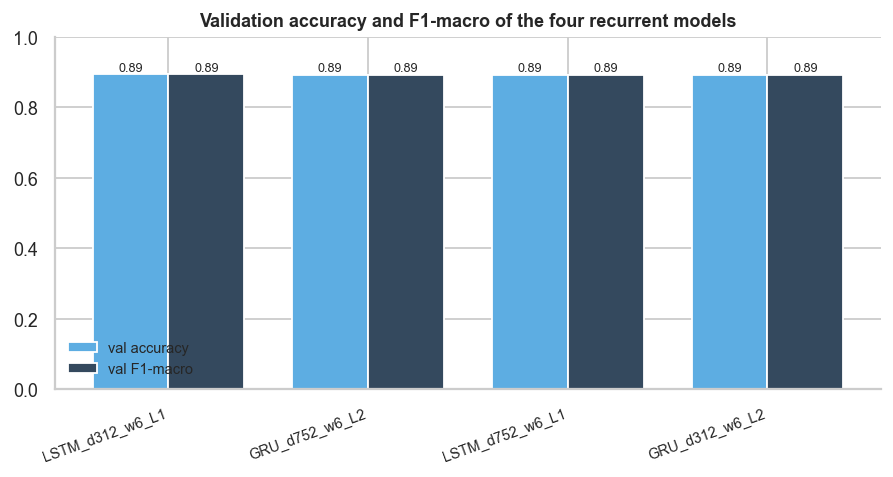

In [24]:
# Figure 1 - compare the four models by accuracy and F1-macro BEFORE any confusion matrix
fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(res)); w = 0.38
ax.bar(x - w/2, res['val_acc'], w, label='val accuracy', color='#5DADE2', edgecolor='white')
ax.bar(x + w/2, res['val_f1_macro'], w, label='val F1-macro', color='#34495E', edgecolor='white')
ax.set_xticks(x); ax.set_xticklabels(res['model'], rotation=20, ha='right', fontsize=8)
ax.set_ylim(0, 1); ax.legend(frameon=False, fontsize=8)
for i, (a, f) in enumerate(zip(res['val_acc'], res['val_f1_macro'])):
    ax.text(i - w/2, a + 0.01, f'{a:.2f}', ha='center', fontsize=7)
    ax.text(i + w/2, f + 0.01, f'{f:.2f}', ha='center', fontsize=7)
ax.set_title('Validation accuracy and F1-macro of the four recurrent models', fontsize=10, fontweight='bold')
plt.tight_layout(); plt.savefig(FIGURES_DIR / 'fig_clf_1_modelcompare.png', bbox_inches='tight'); plt.show()

### 2.3 Learning curves

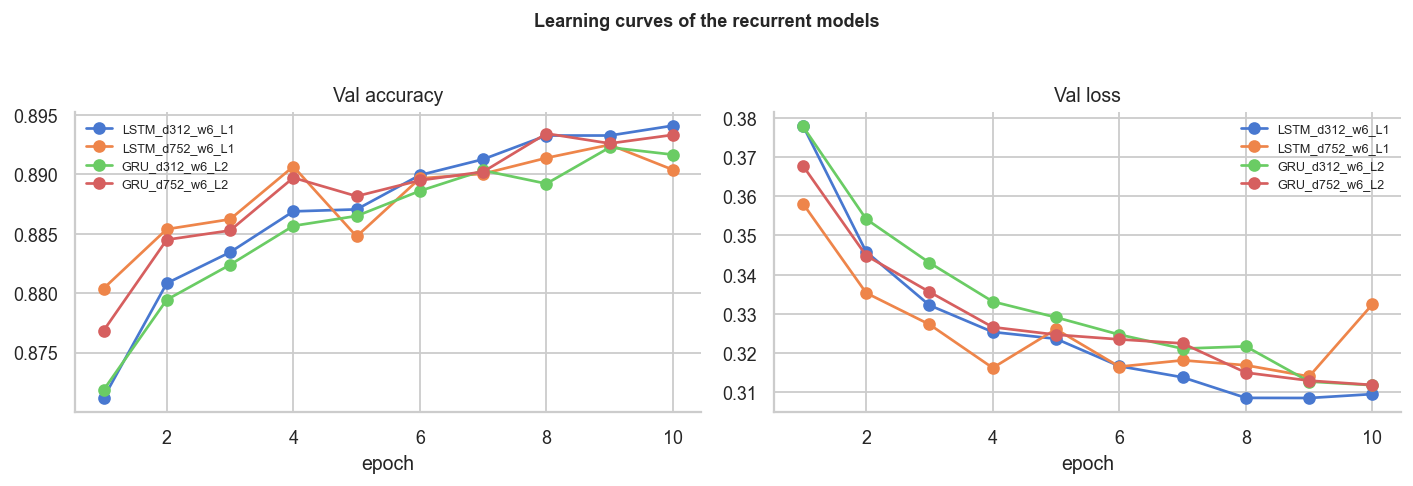

In [25]:
# Figure 2 - validation accuracy and loss per epoch (to argue convergence / overfitting)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name, h in histories.items():
    axes[0].plot(range(1, EPOCHS + 1), h['val_acc'], marker='o', label=name)
    axes[1].plot(range(1, EPOCHS + 1), h['val_loss'], marker='o', label=name)
axes[0].set_title('Val accuracy'); axes[1].set_title('Val loss')
for a in axes: a.set_xlabel('epoch'); a.legend(fontsize=7, frameon=False)
fig.suptitle('Learning curves of the recurrent models', fontsize=10, fontweight='bold', y=1.03)
plt.tight_layout(); plt.savefig(FIGURES_DIR / 'fig_clf_2_curves.png', bbox_inches='tight'); plt.show()

## 3. Evaluation of the best model

### 3.1 Confusion matrices (train vs test)

Best model: LSTM_d312_w6_L1
TEST accuracy=0.898  macro-F1=0.898

Per-class on TEST (precision / recall / F1):
  World      0.924 / 0.875 / 0.899
  Sports     0.942 / 0.964 / 0.953
  Business   0.851 / 0.889 / 0.869
  Sci/Tech   0.879 / 0.866 / 0.873


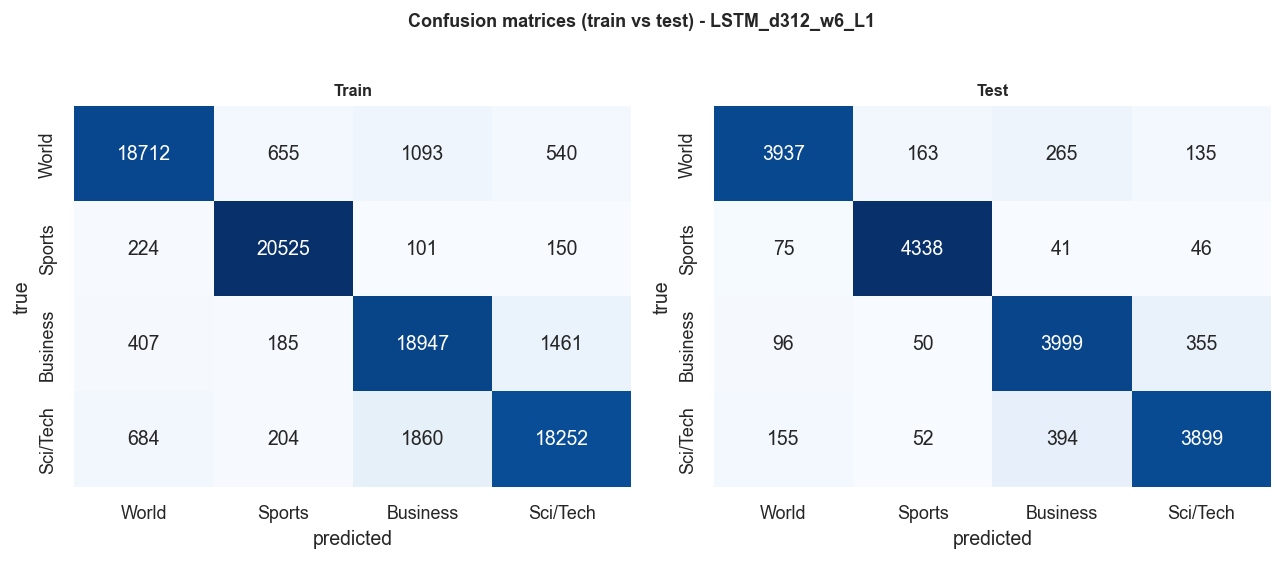

In [26]:
# Confusion helper (numpy) + per-class report; best model chosen from Fig.1
def confusion(y_true, y_pred, k=4):
    cm = np.zeros((k, k), int)
    for t, p in zip(y_true, y_pred): cm[t, p] += 1
    return cm

def plot_cm(ax, cm, title):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(title, fontsize=9, fontweight='bold')

best_name = res.iloc[0]['model']; best = models[best_name]; print('Best model:', best_name)
yp_tr = predict(best, X_tr); yp_te = predict(best, X_te)
print('TEST accuracy=%.3f  macro-F1=%.3f' % ((yp_te == y_te).mean(), macro_f1(y_te, yp_te)))
print('\nPer-class on TEST (precision / recall / F1):')
for c, nm in enumerate(CLASS_NAMES):
    tp = ((yp_te == c) & (y_te == c)).sum(); fp = ((yp_te == c) & (y_te != c)).sum(); fn = ((yp_te != c) & (y_te == c)).sum()
    p = tp / (tp + fp + 1e-9); r = tp / (tp + fn + 1e-9)
    print(f'  {nm:10s} {p:.3f} / {r:.3f} / {2*p*r/(p+r+1e-9):.3f}')

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
plot_cm(axes[0], confusion(y_tr, yp_tr), 'Train')
plot_cm(axes[1], confusion(y_te, yp_te), 'Test')
fig.suptitle(f'Confusion matrices (train vs test) - {best_name}', fontsize=10, fontweight='bold', y=1.02)
plt.tight_layout(); plt.savefig(FIGURES_DIR / 'fig_clf_3_confusion.png', bbox_inches='tight'); plt.show()

### 3.2 Custom web test set (20 real snippets)
An out-of-corpus check: real news headlines collected from the web in June 2026, balanced across
the four categories and kept short (AG-News style).

Web test-set accuracy: 0.90


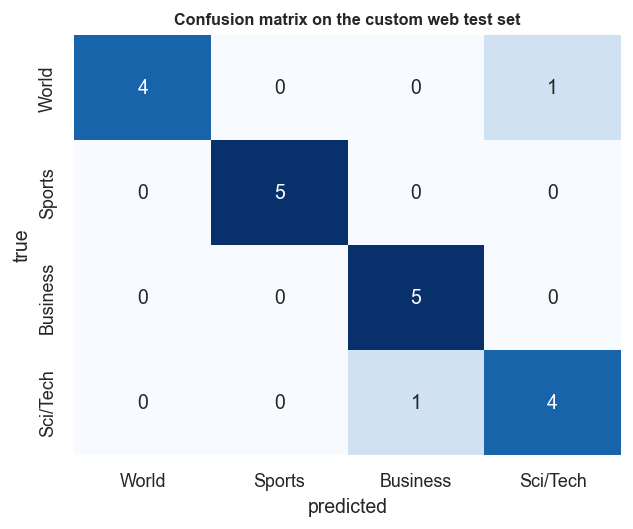

In [28]:
# 20 real web headlines collected June 2026 (balanced, 5 per category), AG-News style.
# Sources: Al Jazeera, CNN, ESPN, Olympics.com,
# FOX Sports, CNBC, ScienceDaily, Quantum Computing Report, imfounder.com.
web_snippets = [
 ('US and Iran sign deal to extend ceasefire and reopen Strait of Hormuz', 'World'),
 ('Israel and Hezbollah agree ceasefire to take effect on Friday', 'World'),
 ('Energy security dominates two-day Russia-ASEAN summit', 'World'),
 ('Pakistan says Islamabad memorandum to end the war takes effect', 'World'),
 ('Iranian attacks on Kuwait airport condemned by Middle East nations', 'World'),
 ('New York Knicks beat San Antonio Spurs 94-90 to win the NBA title', 'Sports'),
 ('Messi scores a hat-trick as Argentina beat Algeria 3-0 at the World Cup', 'Sports'),
 ('Canada crush Qatar 6-0 in the World Cup group stage', 'Sports'),
 ('Ghana edge Panama 1-0 with a last-minute goal', 'Sports'),
 ("A'ja Wilson becomes the fastest player to 6,000 WNBA career points", 'Sports'),
 ('Federal Reserve holds interest rates at 3.5% to 3.75%', 'Business'),
 ('Brent crude oil falls to a three-month low', 'Business'),
 ('CarMax shares rise after an earnings and revenue beat', 'Business'),
 ('La-Z-Boy stock surges 16% on strong retail sales', 'Business'),
 ('Treasury yields jump as markets price in a possible rate hike', 'Business'),
 ('NASA tests a new AI chip to let spacecraft operate on their own', 'Sci/Tech'),
 ('Qualcomm in talks to acquire AI chip maker Tenstorrent', 'Sci/Tech'),
 ('IBM Nighthawk quantum processor validated by two independent studies', 'Sci/Tech'),
 ('WISeKey launches WISeSat 4.0 cybersecurity satellite on a SpaceX rocket', 'Sci/Tech'),
 ('Hackers exploit AI support systems to hijack Instagram accounts', 'Sci/Tech')]

wt = pd.DataFrame(web_snippets, columns=['text', 'label'])
Xw = np.array([encode_pad(t) for t in wt['text']], dtype=np.int64)
yw = wt['label'].map({n: i for i, n in enumerate(CLASS_NAMES)}).values
ypw = predict(best, Xw)
print('Web test-set accuracy: %.2f' % (ypw == yw).mean())

fig, ax = plt.subplots(figsize=(5, 4.2))
plot_cm(ax, confusion(yw, ypw), 'Confusion matrix on the custom web test set')
plt.tight_layout(); plt.savefig(FIGURES_DIR / 'fig_clf_4_webtest.png', bbox_inches='tight'); plt.show()

### 3.3 Analyser for multiple related sentences

In [22]:
# Analyser: classify a list of related sentences with the best model and report confidence
@torch.no_grad()
def analyse(sentences):
    """Return the predicted category and confidence for each sentence using the best model."""
    best.eval()
    Xs = torch.from_numpy(np.array([encode_pad(s) for s in sentences], dtype=np.int64)).to(DEVICE)
    proba = torch.softmax(best(Xs), dim=1).cpu().numpy()
    rows = [{'sentence': s, 'category': CLASS_NAMES[p.argmax()], 'confidence': round(float(p.max()), 3)}
            for s, p in zip(sentences, proba)]
    return pd.DataFrame(rows)

demo = ['The home team secured a dramatic win in the final minute.',
        'Investors reacted nervously as shares fell sharply.',
        'The space agency confirmed the probe entered orbit.',
        'Negotiators reached a fragile peace agreement.']
analyse(demo)

,sentence,category,confidence
0,The home team secured a dramatic win in the fi...,Sports,0.918
1,Investors reacted nervously as shares fell sha...,Business,0.982
2,The space agency confirmed the probe entered o...,Sci/Tech,0.898
3,Negotiators reached a fragile peace agreement.,World,0.634


### 3.4 Summary
- **Model selection**: Fig. 1 compares the four models by accuracy and F1-macro; the best is picked
  before showing its confusion matrix.
- **Training length**: Fig. 2 - training is complete when val loss flattens / starts rising while
  train loss keeps falling; we **restore the best-validation epoch** (early-stopping style).
- **Confusion matrix / generalisation** (Fig. 3, train vs test): the most confused pair is
  Business <-> Sci/Tech, which share vocabulary like *company, market*.
- **Embeddings**: val/test accuracy difference between the two embeddings (Fig. 1 / results table).
- **LSTM vs GRU**: compare the four rows for robustness and training stability.
- **Web test set** (Fig. 4): 20 real headlines, balanced; accuracy and errors vs the held-out test split.